In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

df = pd.read_excel(
    "ebayAuctions.xlsx",
    sheet_name="eBay auctions"
)

df.head()

,Category,Currency,sellerRating,Duration,endDay,ClosePrice,OpenPrice,Competitive?,Unnamed: 8
0,Music/Movie/Game,US,37727.0,7.0,Mon,0.01,0.01,0.0,NaN
1,Music/Movie/Game,US,37727.0,7.0,Mon,4.26,0.01,1.0,NaN
2,SportingGoods,US,34343.0,1.0,Fri,0.11,0.01,1.0,NaN
3,SportingGoods,US,27132.0,5.0,Mon,17.01,0.99,1.0,NaN
4,SportingGoods,US,27132.0,5.0,Mon,19.02,0.99,1.0,NaN


In [2]:
print("Dataset shape:", df.shape)

df.info()
display(df.describe(include="all"))

Dataset shape: (1975, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1975 entries, 0 to 1974
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Category      1972 non-null   object 
 1   Currency      1972 non-null   object 
 2   sellerRating  1972 non-null   float64
 3   Duration      1972 non-null   float64
 4   endDay        1972 non-null   object 
 5   ClosePrice    1972 non-null   float64
 6   OpenPrice     1972 non-null   float64
 7   Competitive?  1974 non-null   float64
 8   Unnamed: 8    1 non-null      float64
dtypes: float64(6), object(3)
memory usage: 139.0+ KB


,Category,Currency,sellerRating,Duration,endDay,ClosePrice,OpenPrice,Competitive?,Unnamed: 8
count,1972,1972,1972.000000,1972.000000,1972,1972.000000,1972.000000,1974.000000,1.000000
unique,18,3,NaN,NaN,7,NaN,NaN,NaN,NaN
top,Music/Movie/Game,US,NaN,NaN,Mon,NaN,NaN,NaN,NaN
freq,403,1292,NaN,NaN,548,NaN,NaN,NaN,NaN
mean,NaN,NaN,3560.238337,6.486308,NaN,36.449087,12.926268,1.905775,0.548535
std,NaN,NaN,5973.011033,2.052906,NaN,89.493858,38.856149,44.670344,NaN
min,NaN,NaN,0.000000,1.000000,NaN,0.010000,0.010000,0.000000,0.548535
25%,NaN,NaN,595.000000,5.000000,NaN,4.907500,1.230000,0.000000,0.548535
50%,NaN,NaN,1853.000000,7.000000,NaN,9.995000,4.500000,1.000000,0.548535
75%,NaN,NaN,3380.000000,7.000000,NaN,28.000000,9.990000,1.000000,0.548535


In [3]:
# Remove irrelevant column
df = df.drop("Unnamed: 8", axis=1)

# Remove extra rows
df = df[df["Competitive?"].isin([0, 1])]

# Reset index
df = df.reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)

Cleaned dataset shape: (1972, 8)


In [4]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)":
        df.isnull().mean() * 100
})

missing_summary

,Missing Count,Missing Percentage (%)
Category,0,0.0
Currency,0,0.0
sellerRating,0,0.0
Duration,0,0.0
endDay,0,0.0
ClosePrice,0,0.0
OpenPrice,0,0.0
Competitive?,0,0.0


In [5]:
df.duplicated().sum()
df[df.duplicated()]

,Category,Currency,sellerRating,Duration,endDay,ClosePrice,OpenPrice,Competitive?
54,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
55,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
56,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
72,Pottery/Glass,GBP,5292.0,7.0,Thu,1.78,1.78,0.0
79,Computer,EUR,3375.0,10.0,Thu,1.23,1.23,0.0
...,...,...,...,...,...,...,...,...
1925,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0
1926,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0
1927,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0
1928,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1972 entries, 0 to 1971
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Category      1972 non-null   object 
 1   Currency      1972 non-null   object 
 2   sellerRating  1972 non-null   float64
 3   Duration      1972 non-null   float64
 4   endDay        1972 non-null   object 
 5   ClosePrice    1972 non-null   float64
 6   OpenPrice     1972 non-null   float64
 7   Competitive?  1972 non-null   float64
dtypes: float64(5), object(3)
memory usage: 123.4+ KB


In [7]:
df.describe()

,sellerRating,Duration,ClosePrice,OpenPrice,Competitive?
count,1972.000000,1972.000000,1972.000000,1972.000000,1972.000000
mean,3560.238337,6.486308,36.449087,12.926268,0.540568
std,5973.011033,2.052906,89.493858,38.856149,0.498478
min,0.000000,1.000000,0.010000,0.010000,0.000000
25%,595.000000,5.000000,4.907500,1.230000,0.000000
50%,1853.000000,7.000000,9.995000,4.500000,1.000000
75%,3380.000000,7.000000,28.000000,9.990000,1.000000
max,37727.000000,10.000000,999.000000,999.000000,1.000000


In [8]:
for col in ["Category", "Currency", "Duration",
            "endDay", "Competitive?"]:
    print(col, df[col].unique())

print("Negative seller ratings:",
      (df["sellerRating"] < 0).sum())

print("Non-positive opening prices:",
      (df["OpenPrice"] <= 0).sum())

print("Non-positive closing prices:",
      (df["ClosePrice"] <= 0).sum())

print("Closing price below opening price:",
      (df["ClosePrice"] < df["OpenPrice"]).sum())

Category ['Music/Movie/Game' 'SportingGoods' 'Business/Industrial' 'Automotive'
 'Collectibles' 'Home/Garden' 'Jewelry' 'Electronics' 'Coins/Stamps'
 'Pottery/Glass' 'Computer' 'Toys/Hobbies' 'Clothing/Accessories'
 'Antique/Art/Craft' 'Books' 'Health/Beauty' 'EverythingElse'
 'Photography']
Currency ['US' 'EUR' 'GBP']
Duration [ 7.  1.  5.  3. 10.]
endDay ['Mon' 'Fri' 'Sun' 'Tue' 'Wed' 'Thu' 'Sat']
Competitive? [0. 1.]
Negative seller ratings: 0
Non-positive opening prices: 0
Non-positive closing prices: 0
Closing price below opening price: 0


In [31]:
categorical_cols = [
    "Category", "Currency", "Duration", "endDay"
]

numerical_cols = [
    "sellerRating", "OpenPrice", "ClosePrice"
]

for col in categorical_cols:
    df[col] = df[col].astype("category")

df["Competitive?"] = df["Competitive?"].astype(int)

In [32]:
target = "Competitive?"

# Model 1: All available predictors
all_predictors = [
    "Category",
    "Currency",
    "sellerRating",
    "Duration",
    "endDay",
    "ClosePrice",
    "OpenPrice"
]

# Model 2 and k-NN: Predictors available before auction
practical_predictors = [
    col for col in all_predictors
    if col != "ClosePrice"
]

In [35]:
train_df, test_df = train_test_split(
    df,
    test_size=0.4,
    random_state=5,
    stratify=df[target]
)

y_train = train_df[target].copy()
y_test = test_df[target].copy()

print("Training set:", train_df.shape)
print("Test set:", test_df.shape)

Training set: (1183, 8)
Test set: (789, 8)


In [ ]:
distribution = pd.DataFrame({
    "Full Dataset":
        df[target].value_counts(normalize=True),

    "Training Set":
        y_train.value_counts(normalize=True),

    "Test Set":
        y_test.value_counts(normalize=True)
}) * 100

display(distribution.round(2))

,Full Dataset,Training Set,Test Set
Competitive?,,,
1,54.06,54.02,54.12
0,45.94,45.98,45.88


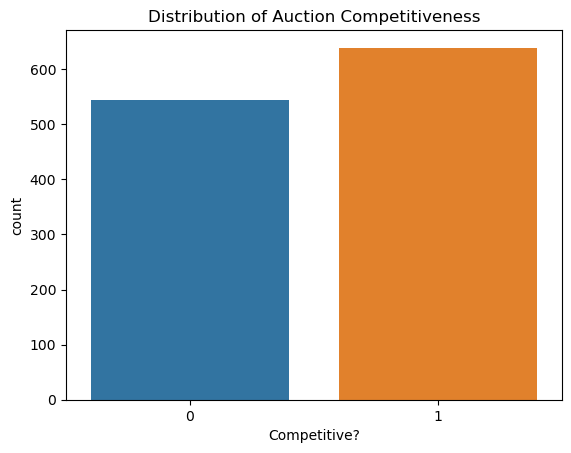

In [47]:
sns.countplot(data=train_df, x="Competitive?")
plt.title("Distribution of Auction Competitiveness")
plt.show()

In [48]:
train_df["Competitive?"].value_counts(normalize=True)

Competitive?
1    0.540152
0    0.459848
Name: proportion, dtype: float64

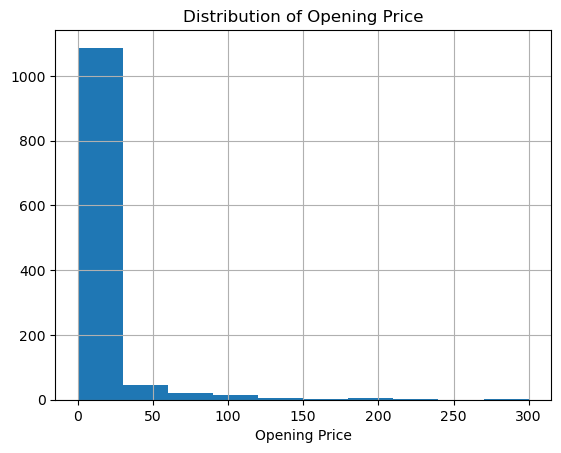

In [49]:
train_df["OpenPrice"].hist()
plt.title("Distribution of Opening Price")
plt.xlabel("Opening Price")
plt.show()